# 6. Geodesic integration and orbit stability
Geodesics follow $\ddot x^\mu=-\Gamma^\mu{}_{\alpha\beta}\dot x^\alpha\dot x^\beta$. We integrate with the package's own Christoffel symbols and monitor (i) the normalisation $g(u,u)=-1$ and (ii) the Killing constants $E=-g(\partial_t,u)$, $L=g(\partial_\phi,u)$.

The effective potential $V=(1-2M/r)(1+L^2/r^2)$ gives circular orbits at $V'=0$, stable when $V''>0$; the marginal case defines the ISCO at $6M$.

ISCO, photon sphere (derived symbolically): [6*M] [3*M]


max |g(u,u)+1| = 4.440892098500626e-15
drift in E, L  = 1.9984014443252818e-15 1.7763568394002505e-14


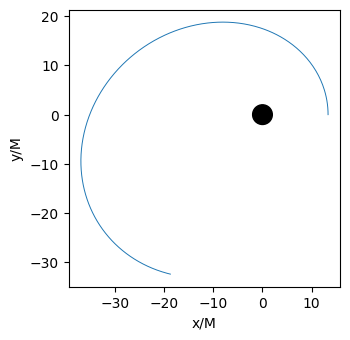

In [1]:
import numpy as np, matplotlib.pyplot as plt
from gr_from_scratch.dynamics import observables as ob
from gr_from_scratch.dynamics.effective_potential import circular_orbit_analysis
from gr_from_scratch.spacetimes.schwarzschild import schwarzschild

print('ISCO, photon sphere (derived symbolically):', circular_orbit_analysis(schwarzschild(), 1)['isco'], circular_orbit_analysis(schwarzschild(), 0)['photon_sphere'])

gs = ob.schwarzschild_system()
E, L, up, ua = ob._orbit_constants(20.0, 0.5, 1.0)
rp = 1/up; f = 1 - 2/rp
tr = gs.integrate(np.array([0, rp, np.pi/2, 0.]), np.array([E/f, 0, 0, L/rp**2]), 600, rtol=1e-12, atol=1e-13, max_step=1.0)
Et, Lp = gs.conserved_function([1,0,0,0]), gs.conserved_function([0,0,0,1])
e = np.array([Et(x,u) for x,u in zip(tr.x, tr.u)]); l = np.array([Lp(x,u) for x,u in zip(tr.x, tr.u)])
print('max |g(u,u)+1| =', abs(tr.constraint).max())
print('drift in E, L  =', abs(e-e[0]).max(), abs(l-l[0]).max())
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.plot(tr.x[:,1]*np.cos(tr.x[:,3]), tr.x[:,1]*np.sin(tr.x[:,3]), lw=0.7)
ax.add_patch(plt.Circle((0,0), 2, color='k')); ax.set_aspect('equal'); ax.set(xlabel='x/M', ylabel='y/M')
plt.show()

**Stability near the ISCO.** Give a circular orbit a small radial kick. Outside $6M$ it oscillates boundedly; inside, it plunges.

In [2]:
def run(r0, T=3000):
    ut = 1/np.sqrt(1 - 3/r0)
    x0 = np.array([0, r0, np.pi/2, 0.]); u0 = np.array([ut, 1e-3, 0, ut/r0**1.5])
    ev = lambda lam, y: y[1] - 2.2
    ev.terminal = True
    return gs.integrate(x0, u0, T, rtol=1e-10, atol=1e-12, events=[ev]).x[:,1]
for r0 in (7.5, 6.5, 5.5, 4.5):
    rr = run(r0)
    print(f'r0={r0}: r stays within [{rr.min():.2f}, {rr.max():.2f}] ->', 'bounded (stable)' if rr.min() > 0.9*r0 and rr.max() < 1.1*r0 else 'plunges (unstable)')

r0=7.5: r stays within [7.46, 7.54] -> bounded (stable)


r0=6.5: r stays within [6.46, 6.54] -> bounded (stable)
r0=5.5: r stays within [2.20, 7.33] -> plunges (unstable)
r0=4.5: r stays within [2.20, 17.99] -> plunges (unstable)
